# Clustering với DBSCAN

Nguồn: https://www.digitalvidya.com/blog/the-top-5-clustering-algorithms-data-scientists-should-know/
![image.png](https://imgur.com/9D6aAF2.gif)

In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plt

np.set_printoptions(precision=3, suppress=True)

## 1. Dữ liệu giả định
(Cùng dữ liệu giả với `03_Demo-kMeans.ipynb`)

In [2]:
np.random.seed(1)
x1,y1 = np.random.normal(loc=2,scale=1,size=50), np.random.normal(loc=5,scale=1,size=50)
x2,y2 = np.random.normal(loc=5,scale=1,size=75), np.random.normal(loc=1,scale=1,size=75)
x3,y3 = np.random.normal(loc=8,scale=1,size=100), np.random.normal(loc=7,scale=1,size=100)

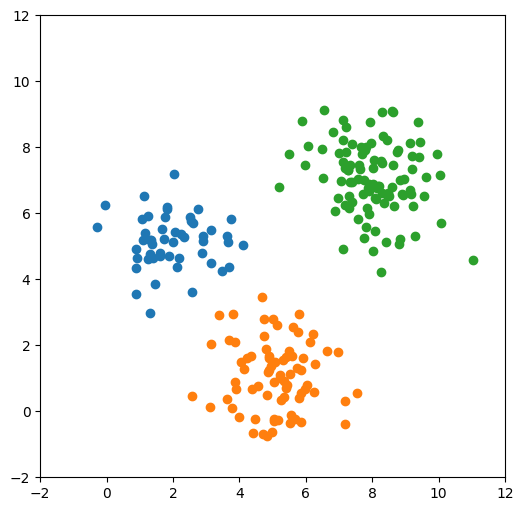

In [3]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(x1, y1)
plt.scatter(x2, y2)
plt.scatter(x3, y3)
plt.show()

### Ghép nối dữ liệu lại thành 1 tập

In [4]:
dat1 = np.stack([x1,y1]).T
dat1.shape

(50, 2)

In [5]:
dat2 = np.stack([x2,y2]).T
dat3 = np.stack([x3,y3]).T

In [6]:
dat = np.vstack([dat1, dat2, dat3])
dat.shape

(225, 2)

### Sắp ngẫu nhiên các dòng

In [7]:
np.random.seed(2)
np.random.shuffle(dat)

### Kiểm tra lại với biểu đồ scatter

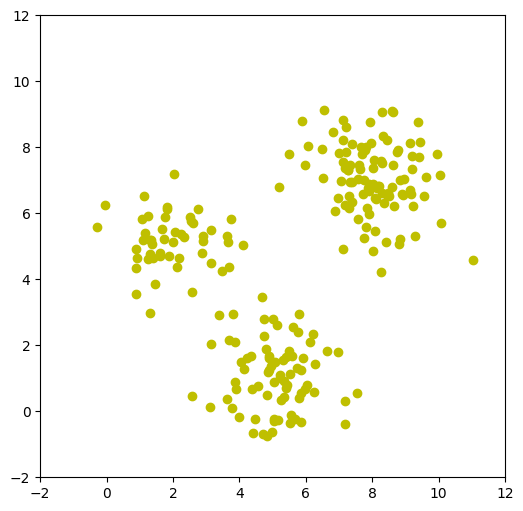

In [8]:
fig = plt.figure(figsize=(6,6))
plt.xlim([-2,12])
plt.ylim([-2,12])

plt.scatter(dat[:,0], dat[:,1], color='y')
plt.show()

## 2. Thực hiện phân cụm bằng DBSCAN

**=== Import lớp DBSCAN từ thư viện sklearn ===**

In [9]:
from sklearn.cluster import DBSCAN

### 2.1. Khởi tạo model và fit vào dữ liệu

In [10]:
eps = 1
minPoints = 5
model = DBSCAN(eps=eps, min_samples=minPoints)

**=== Thực hiện fit vào dữ liệu ===**

In [11]:
model.fit(dat)
print(model)

DBSCAN(eps=1)


### 2.2. Kiểm tra kết quả các cluster tìm được

**=== Lấy ra nhãn các clusters ===**

In [12]:
cluster = model.labels_
print(cluster)

[ 0  0  2  1  1  2  0  1  1  1  1  0  0  2  2  0  2  0  1  2  1  0  0  2
  0  0  1  1  1  0  0  2  2  1  1  1  0  2  2  2  2  2  0 -1  0 -1  1  2
  0  2  0  1  2  0  1  0  0  1  0  0  0  1  0  0  0  0  2  1  2  0  0  0
 -1  2  2  0  0  1  0  0  0  0  0  0  1  0  0 -1 -1  0  0  2  0  0  0  0
  1  1  1  0  0  2  0  0  0  1  1 -1  0 -1  1  0  1  0  0  0  1  1  2  1
  0  0  0  0  0  0  0  2  1  1  2  2  1  0  0  0  2  1  0  0  1  1  2  0
  0  1  0  1  0  1  1  1  0  1  2  1  1  0  1  2  2  0  1  0  2  2  0  1
  1  1  1  1  1  0  0  0  0  0  0  2  2  0  0  1  1  1  0  1  0  2  1  1
  1  0  1  2  2  1  1  1  0  2  1  0  0  2  1  1  0  2  1  2  0  1  0  0
  2  1  1  0  2  2  1  2  0]


In [13]:
cluster

array([ 0,  0,  2,  1,  1,  2,  0,  1,  1,  1,  1,  0,  0,  2,  2,  0,  2,
        0,  1,  2,  1,  0,  0,  2,  0,  0,  1,  1,  1,  0,  0,  2,  2,  1,
        1,  1,  0,  2,  2,  2,  2,  2,  0, -1,  0, -1,  1,  2,  0,  2,  0,
        1,  2,  0,  1,  0,  0,  1,  0,  0,  0,  1,  0,  0,  0,  0,  2,  1,
        2,  0,  0,  0, -1,  2,  2,  0,  0,  1,  0,  0,  0,  0,  0,  0,  1,
        0,  0, -1, -1,  0,  0,  2,  0,  0,  0,  0,  1,  1,  1,  0,  0,  2,
        0,  0,  0,  1,  1, -1,  0, -1,  1,  0,  1,  0,  0,  0,  1,  1,  2,
        1,  0,  0,  0,  0,  0,  0,  0,  2,  1,  1,  2,  2,  1,  0,  0,  0,
        2,  1,  0,  0,  1,  1,  2,  0,  0,  1,  0,  1,  0,  1,  1,  1,  0,
        1,  2,  1,  1,  0,  1,  2,  2,  0,  1,  0,  2,  2,  0,  1,  1,  1,
        1,  1,  1,  0,  0,  0,  0,  0,  0,  2,  2,  0,  0,  1,  1,  1,  0,
        1,  0,  2,  1,  1,  1,  0,  1,  2,  2,  1,  1,  1,  0,  2,  1,  0,
        0,  2,  1,  1,  0,  2,  1,  2,  0,  1,  0,  0,  2,  1,  1,  0,  2,
        2,  1,  2,  0])

**=== Đếm xem mỗi cluster có bao nhiêu điểm ===**

In [14]:
unique, counts = np.unique(cluster, return_counts=True)
print(dict(zip(unique, counts)))

{np.int64(-1): np.int64(7), np.int64(0): np.int64(98), np.int64(1): np.int64(73), np.int64(2): np.int64(47)}


**=== Hiển thị lên biểu đồ ===**

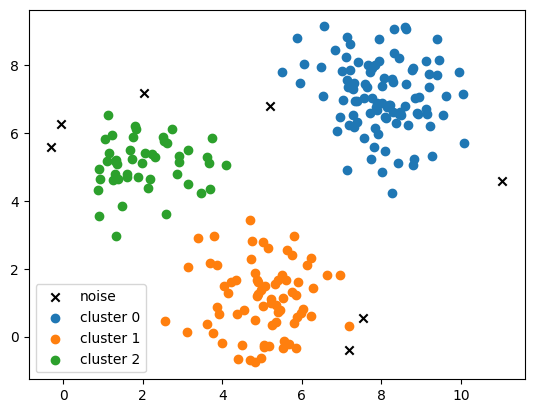

In [15]:
for c in np.unique(cluster):
    pts = dat[cluster == c]
    if c == -1:
        plt.scatter(pts[:,0], pts[:,1], color='black', marker='x', label='noise')
    else:
        plt.scatter(pts[:,0], pts[:,1], label=f'cluster {c}')
plt.legend()

### 2.3. Tính hiệu suất phân cụm

**=== Thử tính với hàm built-in của Sklearn ===**

In [16]:
from sklearn.metrics import silhouette_score

In [17]:
silhouette_score(dat, cluster)

0.639460128792222

**=== Tính lại với các cụm không chứa điểm noise ===**

In [18]:
import pandas as pd

In [19]:
mask = cluster != -1
dat2 = dat[mask]
cluster2 = cluster[mask]

In [20]:
s_list = []

for i, sample in enumerate(dat2):
    label = cluster2[i]
    other_mask = np.arange(len(dat2)) != i
    other_samples = dat2[other_mask]
    other_labels = cluster2[other_mask]
    distances = np.sqrt(np.sum((other_samples - sample)**2, axis=1))
    tmp = pd.DataFrame({'distance': distances, 'cluster': other_labels})
    p = tmp.loc[tmp['cluster'] == label, 'distance'].mean()
    q = tmp.groupby('cluster')['distance'].mean().drop(index=label).min()
    s = (q - p) / max(p, q)
    s_list.append(s)


In [21]:
silhouette_score(dat2, cluster2)

0.68542282500809

**==> Thử thực hiện lại mà không bỏ giá trị noise?**